In [12]:
import geopandas as gpd
import regionmask
import xarray as xr
import os
import netCDF4
import matplotlib.pyplot as plt
import math

In [13]:
os.environ["SHAPE_RESTORE_SHX"] = "YES"

SHAPE_RESTORE_SHX = "YES"
algeria = gpd.read_file("dz.shp")   
ds = xr.open_dataset("data_stream-moda.nc",engine="netcdf4")

mask = regionmask.mask_geopandas(algeria, ds.longitude, ds.latitude)
ds = ds.where(mask.notnull())       
ds = ds.coarsen(latitude=2, longitude=2, boundary="trim").mean()

In [14]:
df = ds.to_dataframe()
df = df.dropna()
df = df.drop(columns=['number','expver'])
df = df.drop_duplicates()
df = df.reset_index()

df

,valid_time,latitude,longitude,d2m,t2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp
0,2015-01-01,36.95,3.75,279.760498,284.346924,-5206072.0,7712772.0,-5404634.0,2.046784e+06,3.819242e-04,-0.002082,2.625080,0.556908,100893.875000,0.005114
1,2015-01-01,36.95,3.95,279.408936,283.862549,-4882846.0,7350362.0,-5204614.0,2.267892e+06,4.743487e-04,-0.001953,2.591389,0.508568,99983.875000,0.005336
2,2015-01-01,36.95,4.35,279.160889,283.442627,-5091602.0,7802930.0,-5141586.0,1.903082e+06,7.885844e-04,-0.002036,2.979572,0.443138,98994.875000,0.006649
3,2015-01-01,36.95,6.35,279.016846,282.479736,-4169095.5,7906041.0,-4781862.0,2.699085e+05,3.262684e-04,-0.001667,2.341633,-0.000465,98126.625000,0.005167
4,2015-01-01,36.95,6.55,279.324310,282.819580,-4094020.0,7723036.5,-4838696.0,7.665407e+05,2.384782e-04,-0.001637,2.287352,-0.045143,98959.210938,0.004703
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
764779,2026-09-01,19.15,3.75,282.029541,307.469238,-203487.0,14447492.0,-9939245.0,-4.292967e+06,1.825392e-07,-0.000081,-0.867740,-1.067228,95788.187500,0.000088
764780,2026-09-01,19.15,3.95,282.064209,307.611816,-261701.5,14496558.0,-9942863.0,-4.281062e+06,2.868474e-07,-0.000105,-0.857364,-1.015471,95966.187500,0.000117
764781,2026-09-01,19.15,4.15,281.926025,307.671875,-213609.0,14506127.0,-9969803.0,-4.307196e+06,1.974404e-07,-0.000085,-0.849551,-0.996916,96068.687500,0.000079
764782,2026-09-01,19.15,4.35,281.761963,307.614258,-188365.0,14641952.0,-9969462.0,-4.458993e+06,7.078052e-08,-0.000075,-0.826602,-0.934172,96013.187500,0.000042


In [15]:
#infos
print(df.shape)
print(df.columns.to_list())

(764784, 15)
['valid_time', 'latitude', 'longitude', 'd2m', 't2m', 'slhf', 'ssr', 'str', 'sshf', 'ro', 'e', 'u10', 'v10', 'sp', 'tp']


In [16]:
#kelvin to celcus
df['t2m'] = df['t2m'] - 273.15   
df['d2m'] = df['d2m'] - 273.15 

In [17]:
df

,valid_time,latitude,longitude,d2m,t2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp
0,2015-01-01,36.95,3.75,6.610504,11.196930,-5206072.0,7712772.0,-5404634.0,2.046784e+06,3.819242e-04,-0.002082,2.625080,0.556908,100893.875000,0.005114
1,2015-01-01,36.95,3.95,6.258942,10.712555,-4882846.0,7350362.0,-5204614.0,2.267892e+06,4.743487e-04,-0.001953,2.591389,0.508568,99983.875000,0.005336
2,2015-01-01,36.95,4.35,6.010895,10.292633,-5091602.0,7802930.0,-5141586.0,1.903082e+06,7.885844e-04,-0.002036,2.979572,0.443138,98994.875000,0.006649
3,2015-01-01,36.95,6.35,5.866852,9.329742,-4169095.5,7906041.0,-4781862.0,2.699085e+05,3.262684e-04,-0.001667,2.341633,-0.000465,98126.625000,0.005167
4,2015-01-01,36.95,6.55,6.174316,9.669586,-4094020.0,7723036.5,-4838696.0,7.665407e+05,2.384782e-04,-0.001637,2.287352,-0.045143,98959.210938,0.004703
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
764779,2026-09-01,19.15,3.75,8.879547,34.319244,-203487.0,14447492.0,-9939245.0,-4.292967e+06,1.825392e-07,-0.000081,-0.867740,-1.067228,95788.187500,0.000088
764780,2026-09-01,19.15,3.95,8.914215,34.461823,-261701.5,14496558.0,-9942863.0,-4.281062e+06,2.868474e-07,-0.000105,-0.857364,-1.015471,95966.187500,0.000117
764781,2026-09-01,19.15,4.15,8.776031,34.521881,-213609.0,14506127.0,-9969803.0,-4.307196e+06,1.974404e-07,-0.000085,-0.849551,-0.996916,96068.687500,0.000079
764782,2026-09-01,19.15,4.35,8.611969,34.464264,-188365.0,14641952.0,-9969462.0,-4.458993e+06,7.078052e-08,-0.000075,-0.826602,-0.934172,96013.187500,0.000042


# univariate analysis

In [18]:
def mediane(df):
       df = df.reset_index(drop=True)
       n = len(df)
       return df[n//2] if n % 2 else (df[n//2 - 1] + df[n//2]) / 2

def mode(df):
    mode_df = df.groupby(df.astype(int)).count()
    return mode_df.idxmax()

### 1. 2m dewpoint temperature

In [19]:
df_sorted = df['d2m'].sort_values()


#mean
d2m_mean = df_sorted.mean()

#mediane
d2m_mediane = mediane(df_sorted)


#mode
d2m_mode = mode(df_sorted)

#variance
d2m_variance = df_sorted.var(ddof=0)

#ecart-type
d2m_ecart_type = math.sqrt(d2m_variance)


print(f"mean : {d2m_mean}")
print(f"mediane: {d2m_mediane}")
print(f"mode: {d2m_mode}")
print(f"variance: {d2m_variance}")
print(f"ecart-type: {d2m_ecart_type}")


 

mean : 1.5400587320327759
mediane: 1.321197509765625
mode: 0
variance: 23.30963706970215
ecart-type: 4.828005496030649


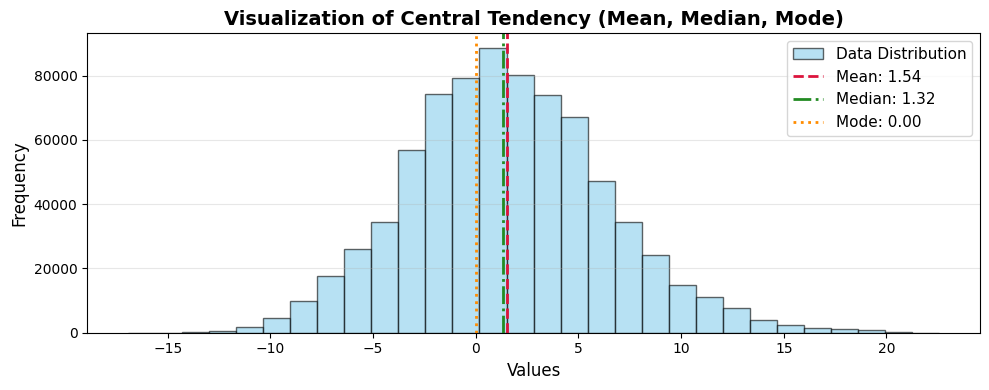

In [20]:
#distribution
plt.figure(figsize=(10, 4))

# Plot the distribution histogram
data = df_sorted
plt.hist(data, bins=30, alpha=0.6, color='skyblue', edgecolor='black', label='Data Distribution')

# Draw vertical lines for each central tendency metric
plt.axvline(d2m_mean, color='crimson', linestyle='--', linewidth=2, label=f'Mean: {d2m_mean:.2f}')
plt.axvline(d2m_mediane, color='forestgreen', linestyle='-.', linewidth=2, label=f'Median: {d2m_mediane:.2f}')
plt.axvline(d2m_mode, color='darkorange', linestyle=':', linewidth=2, label=f'Mode: {d2m_mode:.2f}')

# Customize chart elements
plt.title('Visualization of Central Tendency (Mean, Median, Mode)', fontsize=14, fontweight='bold')
plt.xlabel('Values', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis='y', alpha=0.3)

# Display the plot
plt.tight_layout()
plt.show()

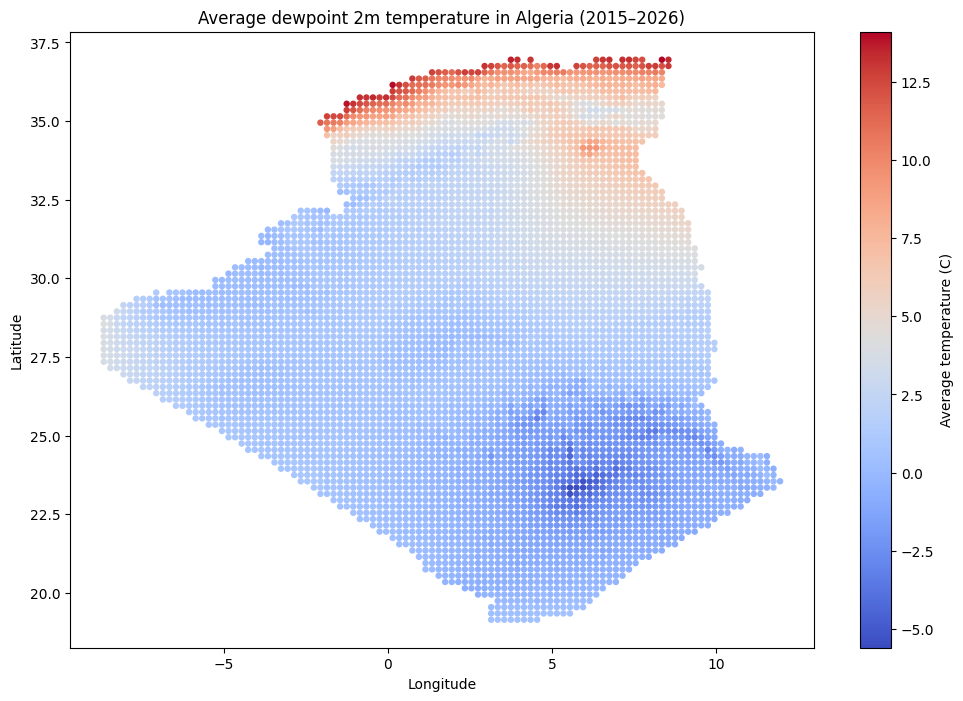

In [21]:


mean_temp = df.groupby(
    ['latitude', 'longitude']
)['d2m'].mean().reset_index()


plt.figure(figsize=(12, 8))

plt.scatter(
    mean_temp['longitude'],
    mean_temp['latitude'],
    c=mean_temp['d2m'],
    cmap='coolwarm',
    s=13
)

plt.colorbar(label='Average temperature (C)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Average dewpoint 2m temperature in Algeria (2015–2026)')
plt.show()

### 2. surface latent heat flux

In [22]:

df_sorted = df['slhf'].sort_values()


#mean
slhf_mean = df_sorted.mean()

#mediane
slhf_mediane = mediane(df_sorted)


#mode
slhf_mode = mode(df_sorted)

#variance
slhf_variance = df_sorted.var(ddof=0)

#ecart-type
slhf_ecart_type = math.sqrt(slhf_variance)


print(f"mean : {slhf_mean}")
print(f"mediane: {slhf_mediane}")
print(f"mode: {slhf_mode}")
print(f"variance: {slhf_variance}")
print(f"ecart-type: {slhf_ecart_type}")


 

mean : -497845.59375
mediane: -182114.0
mode: -44312
variance: 965686591488.0
ecart-type: 982693.5389469089


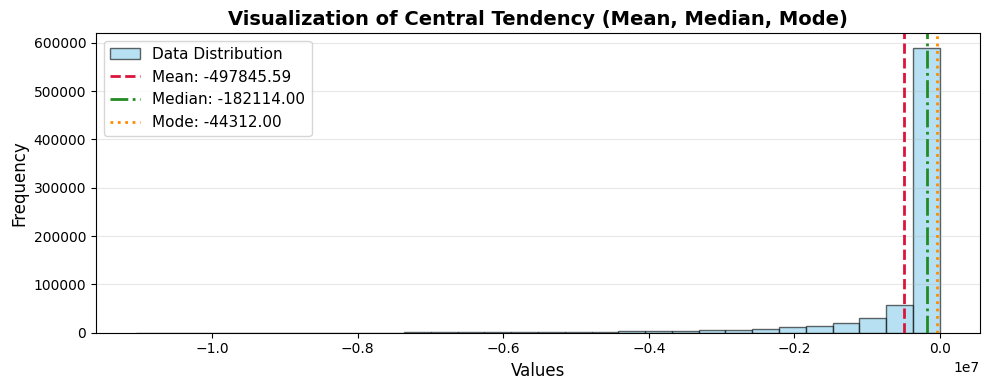

In [23]:
#distribution
plt.figure(figsize=(10, 4))

# Plot the distribution histogram
data = df_sorted
plt.hist(data, bins=30, alpha=0.6, color='skyblue', edgecolor='black', label='Data Distribution')

# Draw vertical lines for each central tendency metric
plt.axvline(slhf_mean, color='crimson', linestyle='--', linewidth=2, label=f'Mean: {slhf_mean:.2f}')
plt.axvline(slhf_mediane, color='forestgreen', linestyle='-.', linewidth=2, label=f'Median: {slhf_mediane:.2f}')
plt.axvline(slhf_mode, color='darkorange', linestyle=':', linewidth=2, label=f'Mode: {slhf_mode:.2f}')

# Customize chart elements
plt.title('Visualization of Central Tendency (Mean, Median, Mode)', fontsize=14, fontweight='bold')
plt.xlabel('Values', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis='y', alpha=0.3)

# Display the plot
plt.tight_layout()
plt.show()

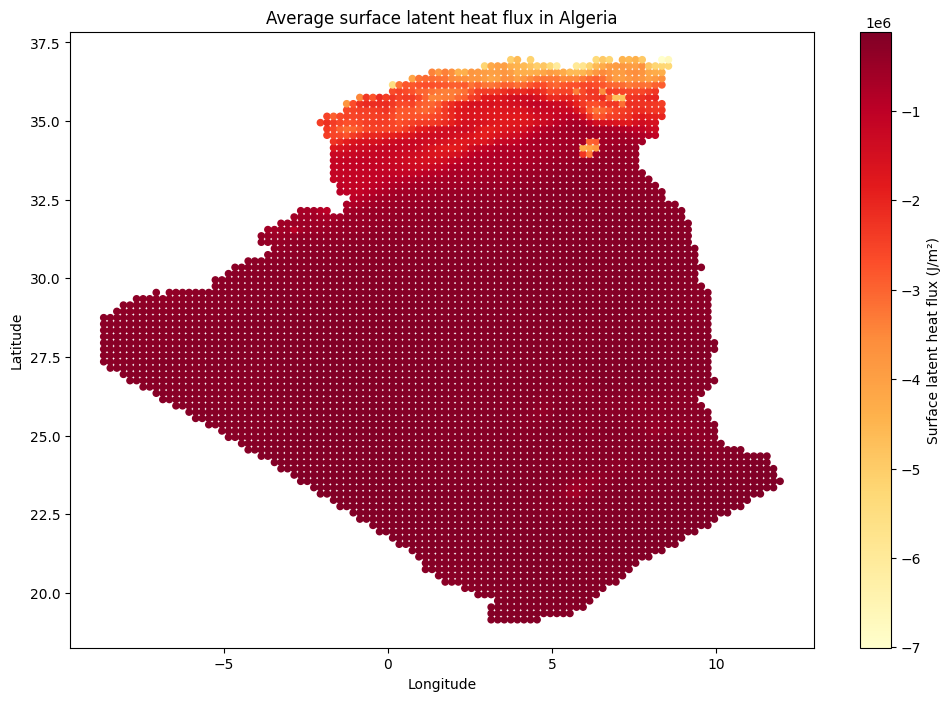

In [24]:
mean_slhf = df.groupby(
    ['latitude', 'longitude']
)['slhf'].mean().reset_index()

fig, ax = plt.subplots(figsize=(12, 8))

sc = ax.scatter(
    mean_slhf['longitude'],
    mean_slhf['latitude'],
    c=mean_slhf['slhf'],
    cmap='YlOrRd',
    s=20
)

plt.colorbar(sc, ax=ax, label='Surface latent heat flux (J/m²)')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Average surface latent heat flux in Algeria')

plt.show()

### 3. surface net solar radiation

In [25]:

df_sorted = df['ssr'].sort_values()


#mean
ssr_mean = df_sorted.mean()

#mediane
ssr_mediane = mediane(df_sorted)


#mode
ssr_mode = mode(df_sorted)

#variance
ssr_variance = df_sorted.var(ddof=0)

#ecart-type
ssr_ecart_type = math.sqrt(ssr_variance)


print(f"mean : {ssr_mean}")
print(f"mediane: {ssr_mediane}")
print(f"mode: {ssr_mode}")
print(f"variance: {ssr_variance}")
print(f"ecart-type: {ssr_ecart_type}")


 

mean : 13510478.0
mediane: 13974622.0
mode: 16994208
variance: 17993931161600.0
ecart-type: 4241925.407359257


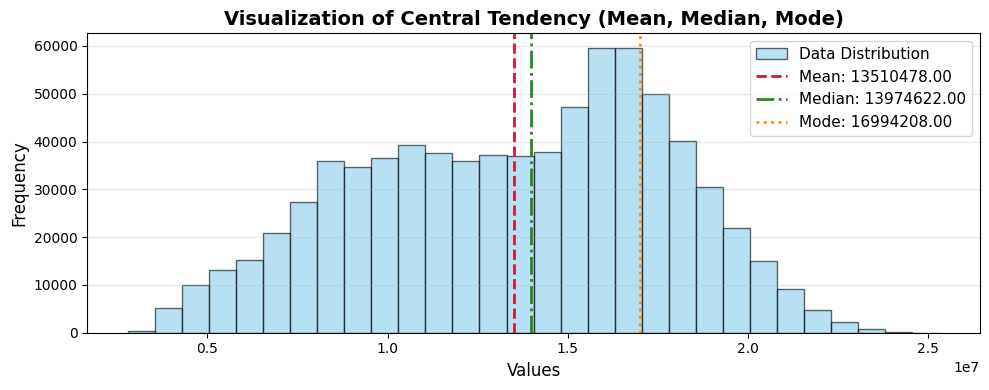

In [26]:
#distribution
plt.figure(figsize=(10, 4))

# Plot the distribution histogram
data = df_sorted
plt.hist(data, bins=30, alpha=0.6, color='skyblue', edgecolor='black', label='Data Distribution')

# Draw vertical lines for each central tendency metric
plt.axvline(ssr_mean, color='crimson', linestyle='--', linewidth=2, label=f'Mean: {ssr_mean:.2f}')
plt.axvline(ssr_mediane, color='forestgreen', linestyle='-.', linewidth=2, label=f'Median: {ssr_mediane:.2f}')
plt.axvline(ssr_mode, color='darkorange', linestyle=':', linewidth=2, label=f'Mode: {ssr_mode:.2f}')

# Customize chart elements
plt.title('Visualization of Central Tendency (Mean, Median, Mode)', fontsize=14, fontweight='bold')
plt.xlabel('Values', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis='y', alpha=0.3)

# Display the plot
plt.tight_layout()
plt.show()

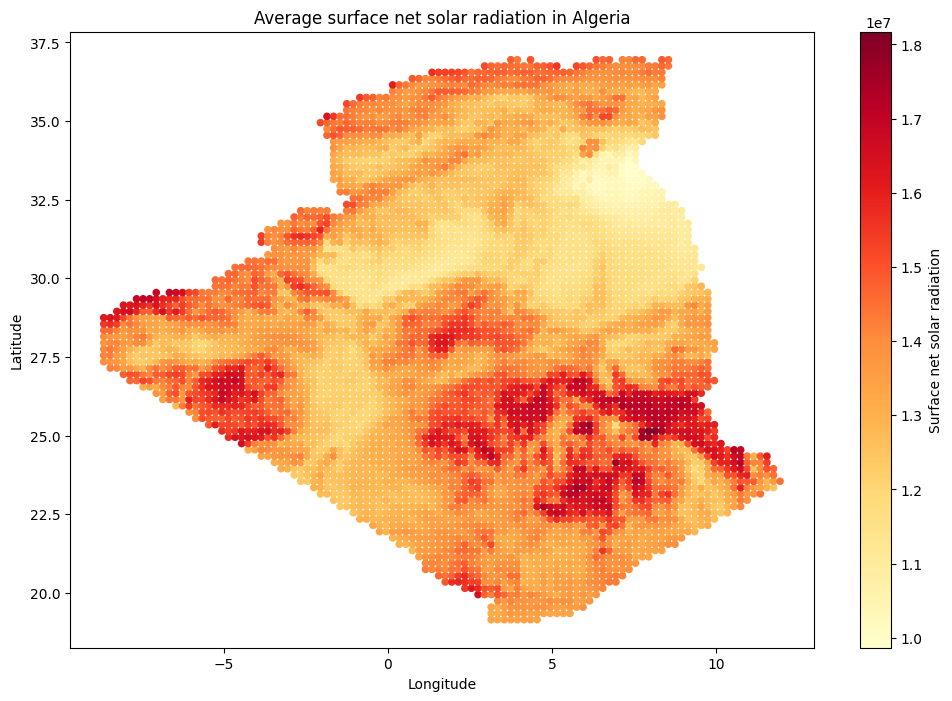

In [27]:
mean_ssr = df.groupby(
    ['latitude', 'longitude']
)['ssr'].mean().reset_index()

fig, ax = plt.subplots(figsize=(12, 8))

sc = ax.scatter(
    mean_ssr['longitude'],
    mean_ssr['latitude'],
    c=mean_ssr['ssr'],
    cmap='YlOrRd',
    s=20
)

plt.colorbar(sc, ax=ax, label='Surface net solar radiation')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Average surface net solar radiation in Algeria')

plt.show()

### 4. surface net thermal radiation

In [28]:

df_sorted = df['str'].sort_values()


#mean
str_mean = df_sorted.mean()

#mediane
str_mediane = mediane(df_sorted)


#mode
str_mode = mode(df_sorted)

#variance
str_variance = df_sorted.var(ddof=0)

#ecart-type
str_ecart_type = math.sqrt(str_variance)


print(f"mean : {str_mean}")
print(f"mediane: {str_mediane}")
print(f"mode: {str_mode}")
print(f"variance: {str_variance}")
print(f"ecart-type: {str_ecart_type}")


 

mean : -9512615.0
mediane: -9921715.0
mode: -12475966
variance: 6784754909184.0
ecart-type: 2604756.2091650725


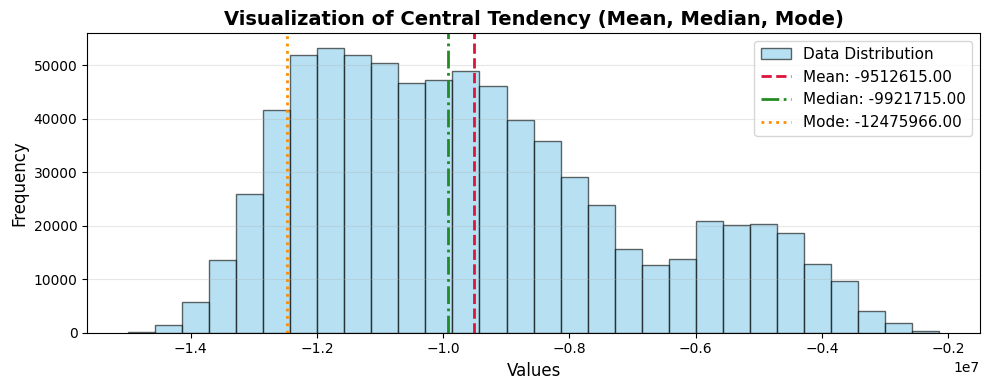

In [29]:
#distribution
plt.figure(figsize=(10, 4))

# Plot the distribution histogram
data = df_sorted
plt.hist(data, bins=30, alpha=0.6, color='skyblue', edgecolor='black', label='Data Distribution')

# Draw vertical lines for each central tendency metric
plt.axvline(str_mean, color='crimson', linestyle='--', linewidth=2, label=f'Mean: {str_mean:.2f}')
plt.axvline(str_mediane, color='forestgreen', linestyle='-.', linewidth=2, label=f'Median: {str_mediane:.2f}')
plt.axvline(str_mode, color='darkorange', linestyle=':', linewidth=2, label=f'Mode: {str_mode:.2f}')

# Customize chart elements
plt.title('Visualization of Central Tendency (Mean, Median, Mode)', fontsize=14, fontweight='bold')
plt.xlabel('Values', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis='y', alpha=0.3)

# Display the plot
plt.tight_layout()
plt.show()

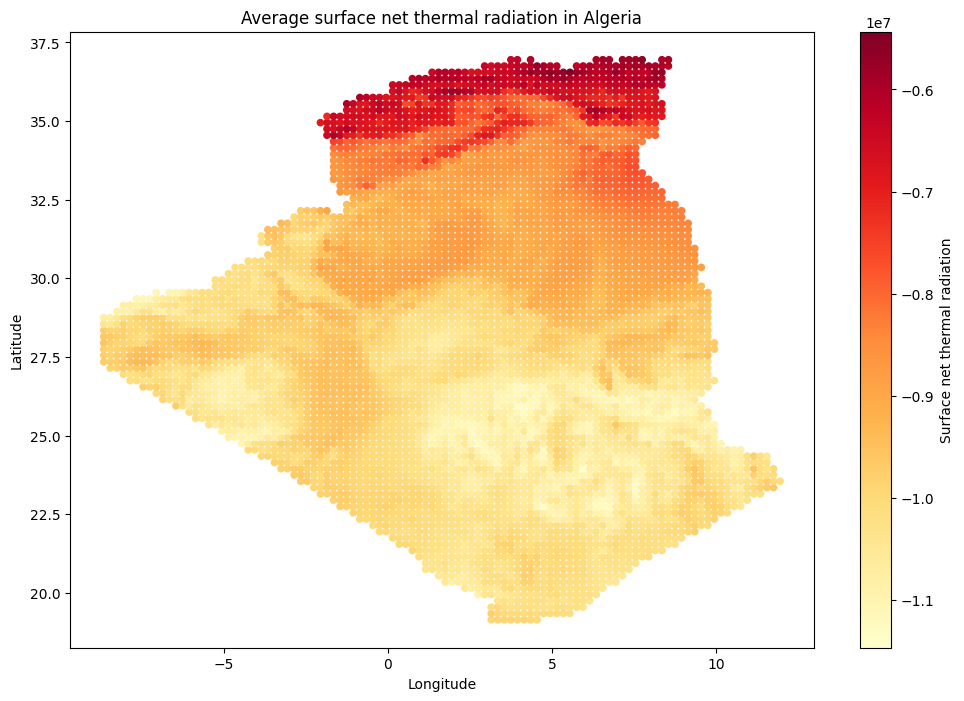

In [30]:
mean_str = df.groupby(
    ['latitude', 'longitude']
)['str'].mean().reset_index()

fig, ax = plt.subplots(figsize=(12, 8))

sc = ax.scatter(
    mean_str['longitude'],
    mean_str['latitude'],
    c=mean_str['str'],
    cmap='YlOrRd',
    s=20
)

plt.colorbar(sc, ax=ax, label='Surface net thermal radiation')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Average surface net thermal radiation in Algeria')

plt.show()

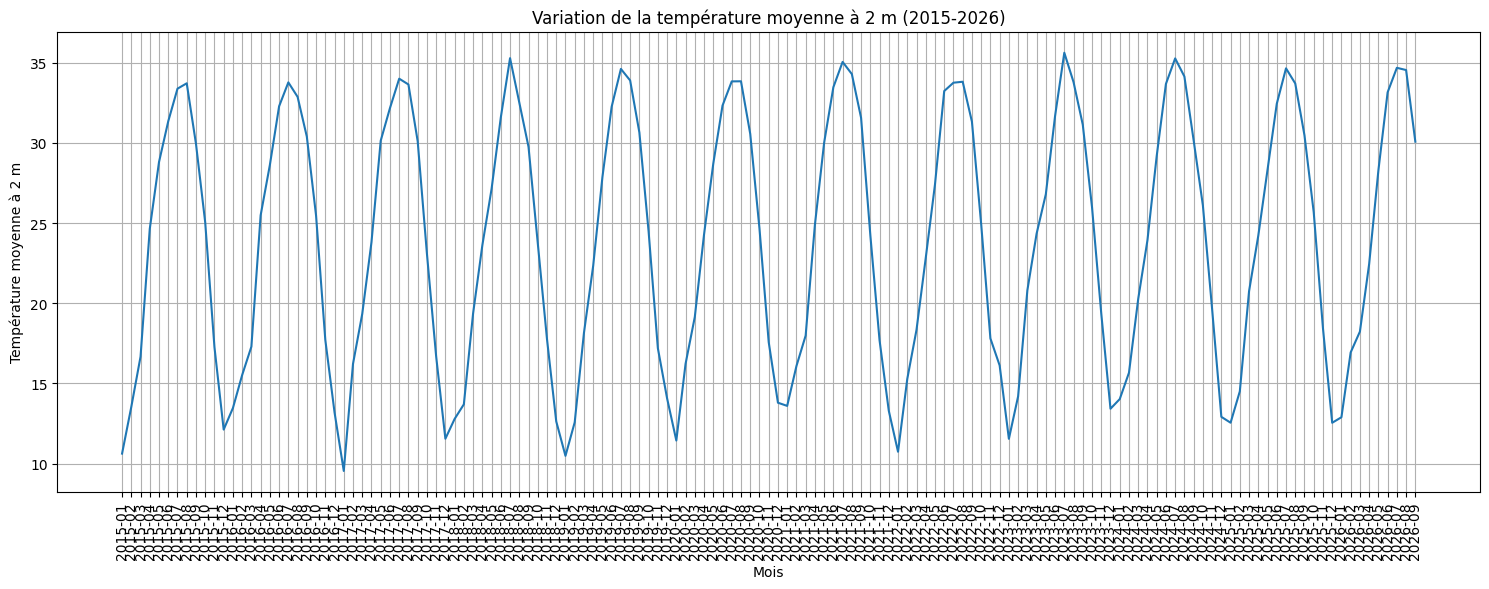

In [31]:
import pandas as pd
#variation de la temperature moyenne a 2m chaque mois entre 2015 et 2026
df['valid_time'] = pd.to_datetime(df['valid_time'])
monthly_temp = df.groupby(
    df['valid_time'].dt.to_period('M')
)['t2m'].mean()

plt.figure(figsize=(15, 6))

plt.plot(monthly_temp.index.astype(str), monthly_temp.values)

plt.title("Variation de la température moyenne à 2 m (2015-2026)")
plt.xlabel("Mois")
plt.ylabel("Température moyenne à 2 m")
plt.xticks(rotation=90)
plt.grid(True)

plt.tight_layout()
plt.show()